# Figure 1 — Plotting and assembly

This notebook reads only the panel-ready CSV files produced by `01_Figure1_Analysis.ipynb`.

It performs no downloads and no statistical modeling. Styling can be revised here without changing the locked analysis outputs.

The revised five-panel layout is:

```text
              A
          B       C
          D       E
```

The former adjusted E-MTAB panel is retained by the analysis notebook as a Table 1 candidate and is not assembled into Figure 1.


In [8]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage, ImageChops, ImageOps
from IPython.display import Image as DisplayImage, display

PROJECT_ROOT = Path("/scratch/ar58064/mitoxy")
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "figure_1_clean"
FIGURE_DIR = PROJECT_ROOT / "figures" / "figure_1_clean"
PANEL_DIR = FIGURE_DIR / "panels"
PANEL_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(DATA_DIR / "figure_1_processed_manifest.csv")
assert manifest["path"].map(lambda value: Path(value).exists()).all()

panel_b = pd.read_csv(DATA_DIR / "panel_b_grade_summary.csv")
panel_c = pd.read_csv(DATA_DIR / "panel_c_stage_summary.csv")
panel_d = pd.read_csv(DATA_DIR / "panel_d_cptac_coherence.csv")
panel_e = pd.read_csv(DATA_DIR / "panel_e_tracerx_summary.csv")

COLORS = {
    "TCGA-KIRC": "#0072B2",
    "CPTAC": "#D55E00",
    "E-MTAB-1980": "#009E73",
    "TRACERx": "#7A5195",
}

DARK_TEXT = "#27313D"
MID_TEXT = "#596574"
LIGHT_TEXT = "#778290"
BAND = "#F3F6F8"
GRID = "#DCE3E8"
WHITE = "#FFFFFF"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})

## Shared plotting functions


In [9]:
def save_panel(fig, stem):
    paths = {
        suffix: PANEL_DIR / f"{stem}.{suffix}"
        for suffix in ["png", "svg", "pdf"]
    }
    for suffix, path in paths.items():
        options = {"bbox_inches": "tight", "facecolor": WHITE}
        if suffix == "png":
            options["dpi"] = 400
        fig.savefig(path, **options)
    return paths


def forest_panel(data, panel_letter, endpoint_label, stem, xlim=(-0.05, 0.72)):
    order = ["TCGA-KIRC", "CPTAC", "E-MTAB-1980", "TRACERx"]
    plot_data = data.set_index("cohort").loc[order].reset_index()
    y = np.arange(len(plot_data) - 1, -1, -1)

    fig, ax = plt.subplots(figsize=(12.2, 7.0))
    fig.patch.set_facecolor(WHITE)

    for number, y_value in enumerate(y):
        if number % 2 == 0:
            ax.axhspan(y_value - 0.43, y_value + 0.43, color=BAND, zorder=0)

    ax.axvline(0, color="#AEB8C2", linestyle=(0, (4, 4)), linewidth=1.8)

    labels = []
    for y_value, row in zip(y, plot_data.itertuples(index=False)):
        color = COLORS[row.cohort]
        ax.hlines(y_value, row.ci_low, row.ci_high, color=color, linewidth=5)
        ax.vlines([row.ci_low, row.ci_high], y_value - 0.12, y_value + 0.12,
                  color=color, linewidth=2.8)
        ax.scatter(row.rho, y_value, s=300, color=color, edgecolor=WHITE,
                   linewidth=2.5, zorder=4)
        p_text = (
            f"{row.p_value:.1e}"
            if row.p_value < 0.001
            else f"{row.p_value:.3f}"
        )
        ax.text(xlim[1] - 0.035, y_value,
                f"$\\rho$ = {row.rho:.2f}\n$P$ = {p_text}",
                ha="right", va="center", fontsize=13, fontweight="bold",
                color=color, linespacing=1.25,
                bbox={"boxstyle": "round,pad=0.45",
                      "facecolor": (1, 1, 1, 0.86),
                      "edgecolor": color, "linewidth": 1.5})
        labels.append(f"{row.cohort}   $n$={int(row.n)}")

    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=14)
    ax.set_xlim(*xlim)
    ax.set_xlabel(rf"Spearman correlation with {endpoint_label} ($\rho$)",
                  fontsize=16, labelpad=18)
    ax.grid(axis="x", color=GRID, linewidth=1.1)
    ax.tick_params(axis="y", length=0, pad=14)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color("#8B96A3")
    fig.text(0.025, 0.955, panel_letter, fontsize=34, fontweight="bold",
             color=DARK_TEXT, ha="left", va="top")
    fig.subplots_adjust(left=0.27, right=0.96, top=0.90, bottom=0.18)
    paths = save_panel(fig, stem)
    plt.show()
    return paths

## Panel A — study overview


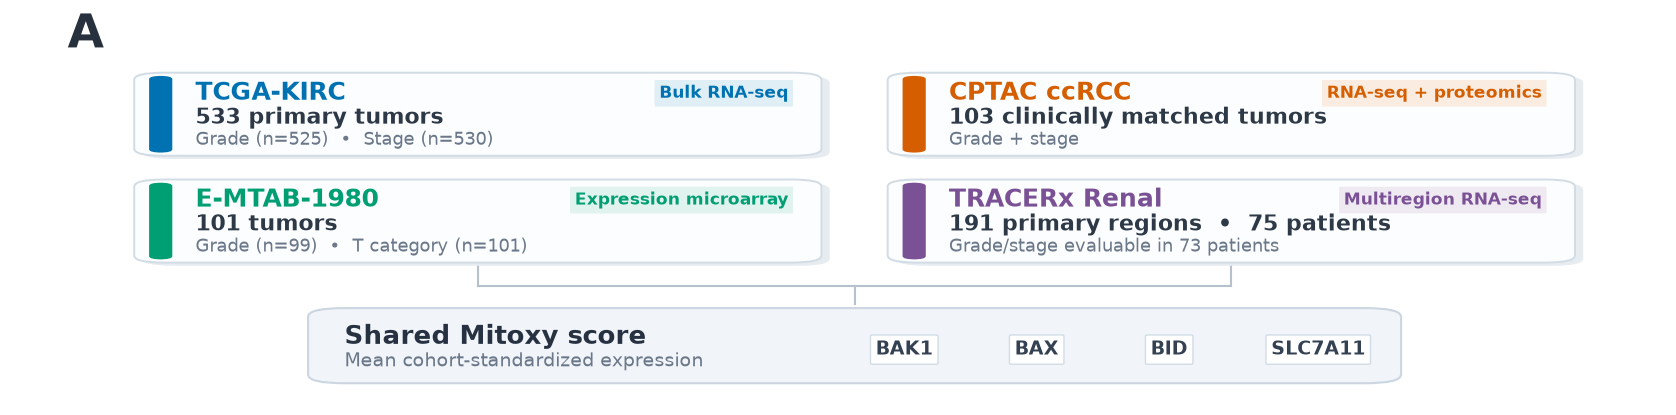

In [10]:
from matplotlib.colors import to_rgb
from matplotlib.patches import FancyBboxPatch


def pale_tint(color, strength=0.88):
    rgb = np.array(to_rgb(color))
    return tuple(rgb * (1 - strength) + np.ones(3) * strength)


def rounded_box(ax, xy, width, height, facecolor, edgecolor,
                radius=0.018, linewidth=1.4, zorder=2):
    patch = FancyBboxPatch(
        xy,
        width,
        height,
        boxstyle=f"round,pad=0.0,rounding_size={radius}",
        transform=ax.transAxes,
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        zorder=zorder,
    )
    ax.add_patch(patch)
    return patch


# Match the wide aspect ratio of Panel A's final assembly slot so the
# overview fills the row instead of being reduced by contain-scaling.
fig, ax = plt.subplots(figsize=(18.0, 4.3))
fig.patch.set_facecolor(WHITE)
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
fig.subplots_adjust(left=0.06, right=0.98, top=0.96, bottom=0.04)

# Anchor the panel letter to the card grid rather than the outer canvas.
fig.text(0.092, 0.955, "A", fontsize=34, fontweight="bold", color=DARK_TEXT,
         ha="left", va="top")

cards = [
    {
        "cohort": "TCGA-KIRC",
        "title": "TCGA-KIRC",
        "tag": "Bulk RNA-seq",
        "main": "533 primary tumors",
        "detail": "Grade (n=525)  •  Stage (n=530)",
        "x": 0.075,
        "y": 0.63,
    },
    {
        "cohort": "CPTAC",
        "title": "CPTAC ccRCC",
        "tag": "RNA-seq + proteomics",
        "main": "103 clinically matched tumors",
        "detail": "Grade + stage",
        "x": 0.53,
        "y": 0.63,
    },
    {
        "cohort": "E-MTAB-1980",
        "title": "E-MTAB-1980",
        "tag": "Expression microarray",
        "main": "101 tumors",
        "detail": "Grade (n=99)  •  T category (n=101)",
        "x": 0.075,
        "y": 0.36,
    },
    {
        "cohort": "TRACERx",
        "title": "TRACERx Renal",
        "tag": "Multiregion RNA-seq",
        "main": "191 primary regions  •  75 patients",
        "detail": "Grade/stage evaluable in 73 patients",
        "x": 0.53,
        "y": 0.36,
    },
]

card_width = 0.415
card_height = 0.21

# Connector from all four cohorts to the shared score definition.
connector = "#B6C1CC"
ax.plot([0.2825, 0.2825], [0.36, 0.30], color=connector, linewidth=1.5,
        transform=ax.transAxes, zorder=0)
ax.plot([0.7375, 0.7375], [0.36, 0.30], color=connector, linewidth=1.5,
        transform=ax.transAxes, zorder=0)
ax.plot([0.2825, 0.7375], [0.30, 0.30], color=connector, linewidth=1.5,
        transform=ax.transAxes, zorder=0)
ax.plot([0.51, 0.51], [0.30, 0.255], color=connector, linewidth=1.5,
        transform=ax.transAxes, zorder=0)

for card in cards:
    color = COLORS[card["cohort"]]
    x, y = card["x"], card["y"]

    rounded_box(
        ax, (x + 0.005, y - 0.008), card_width, card_height,
        facecolor="#E7ECF1", edgecolor="none", zorder=1,
    )
    rounded_box(
        ax, (x, y), card_width, card_height,
        facecolor="#FCFDFE", edgecolor="#D2DCE5", zorder=2,
    )
    rounded_box(
        ax, (x + 0.009, y + 0.008), 0.014, card_height - 0.016,
        facecolor=color, edgecolor=color, radius=0.008,
        linewidth=0, zorder=3,
    )

    ax.text(x + 0.037, y + 0.158, card["title"],
            transform=ax.transAxes, fontsize=18.0, fontweight="bold",
            color=color, ha="left", va="center", zorder=4)

    ax.text(x + card_width - 0.020, y + 0.158, card["tag"],
            transform=ax.transAxes, fontsize=12.3, fontweight="bold",
            color=color, ha="right", va="center", zorder=4,
            bbox={"boxstyle": "round,pad=0.28,rounding_size=0.08",
                  "facecolor": pale_tint(color, 0.88),
                  "edgecolor": "none"})

    ax.text(x + 0.037, y + 0.096, card["main"],
            transform=ax.transAxes, fontsize=15.8, fontweight="bold",
            color="#2E3948", ha="left", va="center", zorder=4)
    ax.text(x + 0.037, y + 0.040, card["detail"],
            transform=ax.transAxes, fontsize=13.2,
            color="#6B788A", ha="left", va="center", zorder=4)

# Shared score definition.
score_x, score_y = 0.18, 0.055
score_width, score_height = 0.66, 0.19
rounded_box(
    ax, (score_x, score_y), score_width, score_height,
    facecolor="#F1F4F8", edgecolor="#CBD6E0",
    radius=0.022, linewidth=1.5, zorder=2,
)

ax.text(score_x + 0.022, score_y + 0.117, "Shared Mitoxy score",
        transform=ax.transAxes, fontsize=18.5, fontweight="bold",
        color="#263242", ha="left", va="center", zorder=4)
ax.text(score_x + 0.022, score_y + 0.055,
        "Mean cohort-standardized expression",
        transform=ax.transAxes, fontsize=13.4,
        color="#6B788A", ha="left", va="center", zorder=4)

gene_positions = [0.54, 0.62, 0.70, 0.79]
for gene, gene_x in zip(["BAK1", "BAX", "BID", "SLC7A11"], gene_positions):
    ax.text(gene_x, score_y + 0.085, gene,
            transform=ax.transAxes, fontsize=13.5, fontweight="bold",
            color="#344152", ha="center", va="center", zorder=4,
            bbox={"boxstyle": "round,pad=0.28,rounding_size=0.08",
                  "facecolor": WHITE, "edgecolor": "#D2DCE5",
                  "linewidth": 1.0})

panel_a_paths = save_panel(fig, "figure_1a_cohort_overview")
plt.show()

## Panels B and C — clinical associations


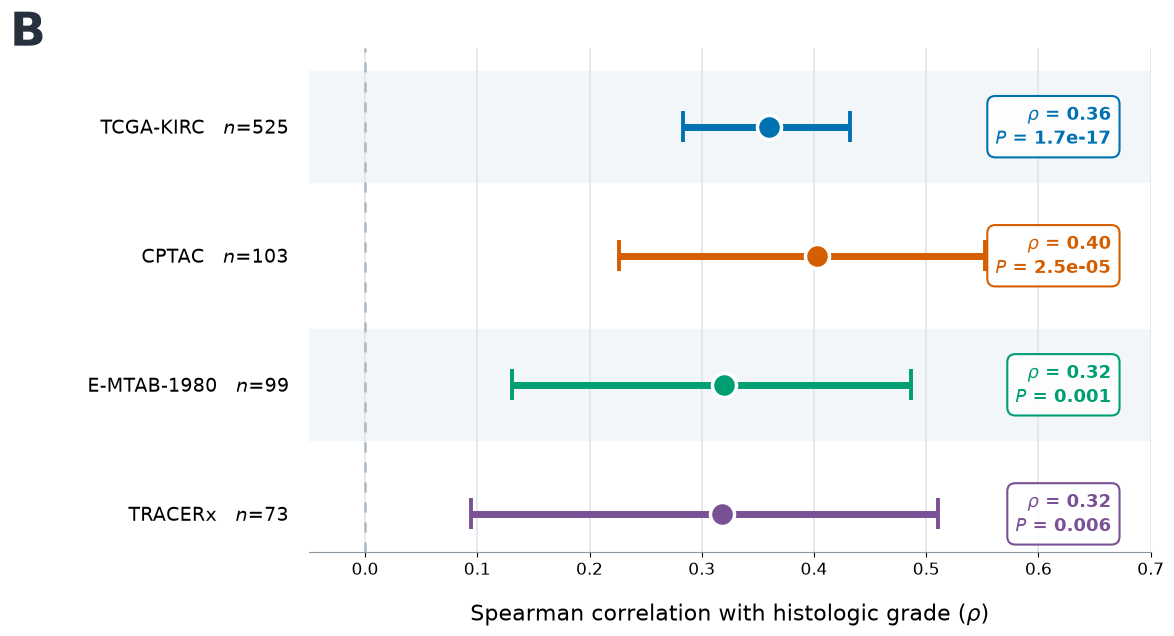

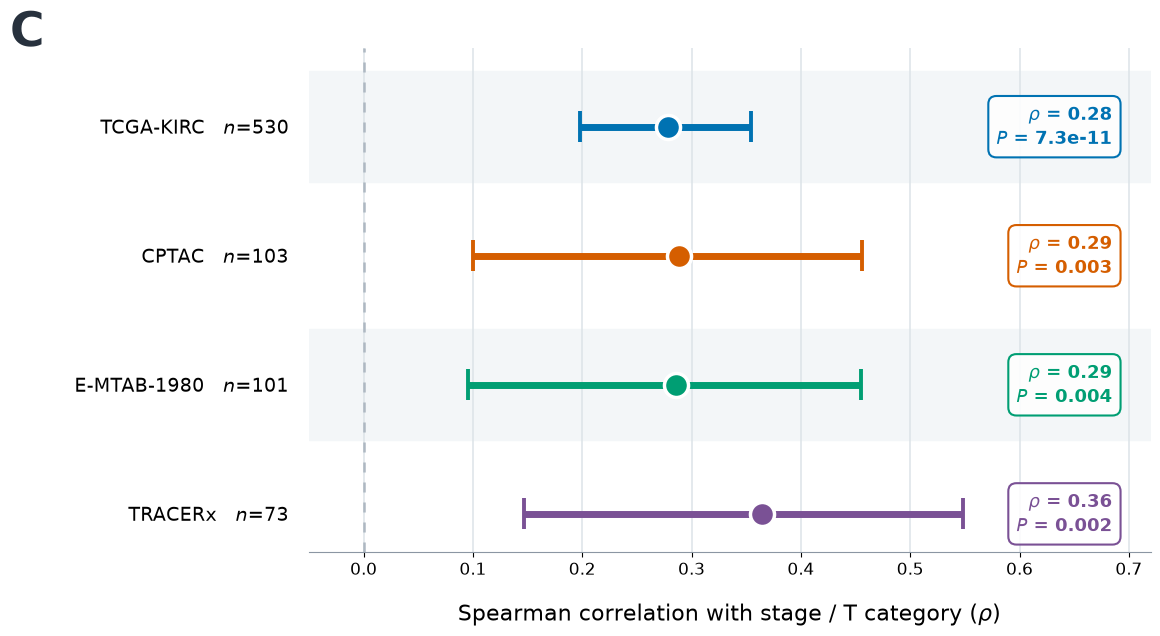

In [11]:
panel_b_paths = forest_panel(
    panel_b, "B", "histologic grade", "figure_1b_grade_associations",
    xlim=(-0.05, 0.70),
)

panel_c_paths = forest_panel(
    panel_c, "C", "stage / T category", "figure_1c_stage_associations",
    xlim=(-0.05, 0.72),
)


## Panel D — CPTAC cross-molecular coherence


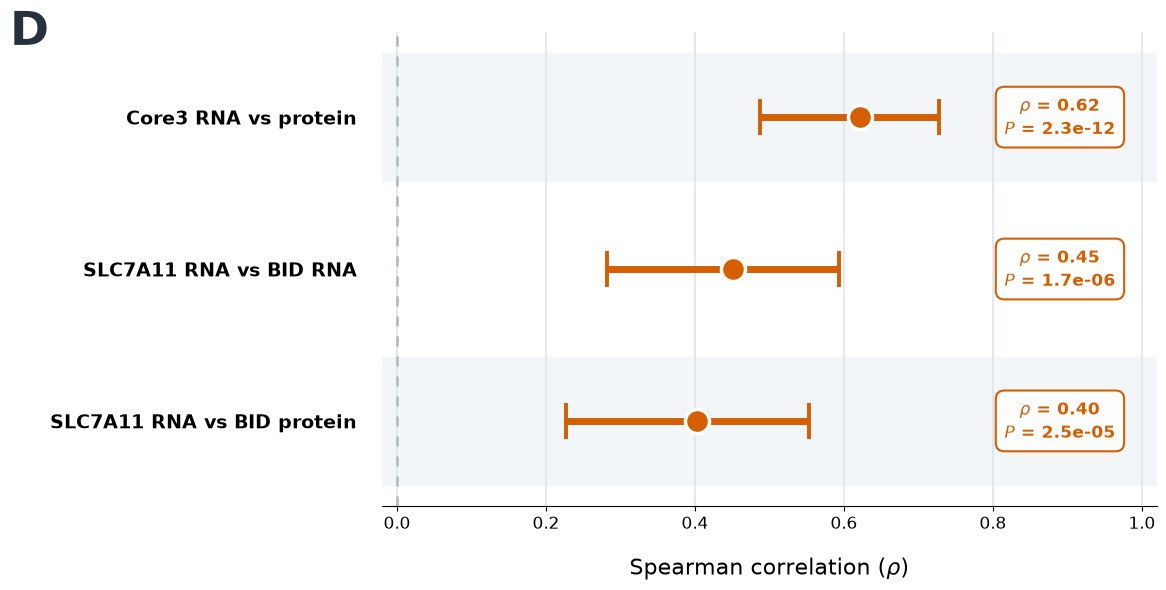

In [12]:
fig, ax = plt.subplots(figsize=(12.2, 6.5))
fig.patch.set_facecolor(WHITE)
y = np.arange(len(panel_d) - 1, -1, -1)
orange = COLORS["CPTAC"]

for number, y_value in enumerate(y):
    if number % 2 == 0:
        ax.axhspan(y_value - 0.42, y_value + 0.42, color=BAND, zorder=0)
ax.axvline(0, color="#AEB8C2", linestyle=(0, (4, 4)), linewidth=1.8)

for y_value, row in zip(y, panel_d.itertuples(index=False)):
    ax.hlines(y_value, row.ci_low, row.ci_high, color=orange, linewidth=5)
    ax.vlines([row.ci_low, row.ci_high], y_value - 0.12, y_value + 0.12,
              color=orange, linewidth=2.8)
    ax.scatter(row.rho, y_value, s=300, color=orange, edgecolor=WHITE,
               linewidth=2.5, zorder=4)
    p_text = (
        f"{row.p_value:.1e}"
        if row.p_value < 0.001
        else f"{row.p_value:.3f}"
    )
    ax.text(0.89, y_value,
            f"$\\rho$ = {row.rho:.2f}\n$P$ = {p_text}",
            ha="center", va="center", fontsize=12.5, fontweight="bold",
            color=orange, linespacing=1.25,
            bbox={"boxstyle": "round,pad=0.5",
                  "facecolor": (1, 1, 1, 0.86),
                  "edgecolor": orange, "linewidth": 1.5})

ax.set_yticks(y)
ax.set_yticklabels(panel_d["comparison"], fontsize=14, fontweight="bold")
ax.set_xlim(-0.02, 1.02)
ax.set_xlabel(r"Spearman correlation ($\rho$)", fontsize=16, labelpad=18)
ax.grid(axis="x", color=GRID, linewidth=1.1)
ax.tick_params(axis="y", length=0, pad=18)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
fig.text(0.025, 0.955, "D", fontsize=34, fontweight="bold", color=DARK_TEXT,
         ha="left", va="top")
fig.subplots_adjust(left=0.33, right=0.965, top=0.92, bottom=0.19)
panel_d_paths = save_panel(fig, "figure_1d_cptac_coherence")
plt.show()

## Panel E — TRACERx sampling robustness


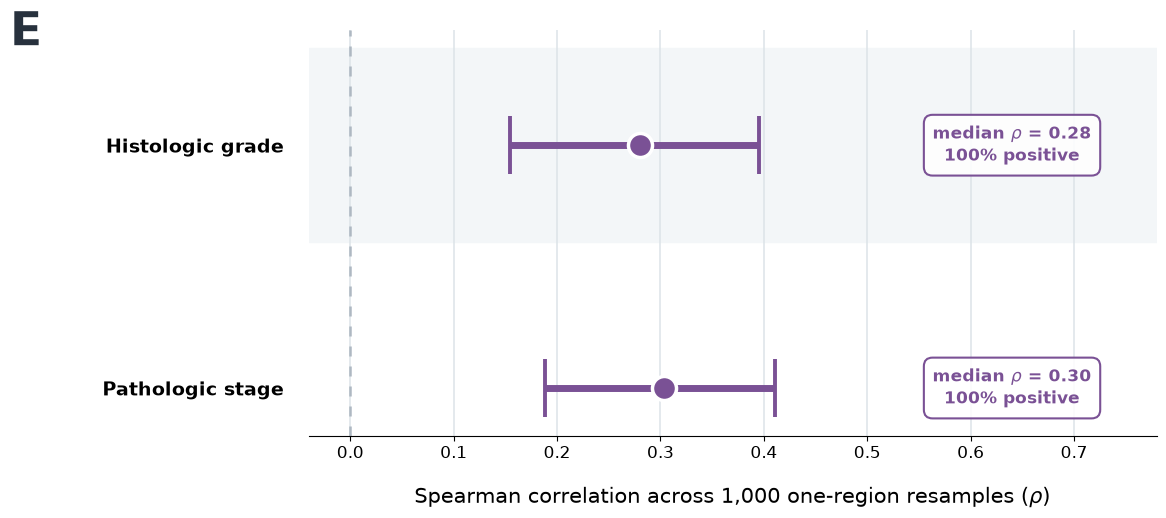

In [13]:
fig, ax = plt.subplots(figsize=(12.2, 5.8))
fig.patch.set_facecolor(WHITE)
y = np.arange(len(panel_e) - 1, -1, -1)
purple = COLORS["TRACERx"]

for number, y_value in enumerate(y):
    if number % 2 == 0:
        ax.axhspan(y_value - 0.40, y_value + 0.40, color=BAND, zorder=0)
ax.axvline(0, color="#AEB8C2", linestyle=(0, (4, 4)), linewidth=1.8)

for y_value, row in zip(y, panel_e.itertuples(index=False)):
    ax.hlines(y_value, row.q025, row.q975, color=purple, linewidth=5)
    ax.vlines([row.q025, row.q975], y_value - 0.12, y_value + 0.12,
              color=purple, linewidth=2.8)
    ax.scatter(row.median, y_value, s=300, color=purple, edgecolor=WHITE,
               linewidth=2.5, zorder=4)
    ax.text(0.64, y_value,
            f"median $\\rho$ = {row.median:.2f}\n"
            f"{100*row.direction_positive_frac:.0f}% positive",
            ha="center", va="center", fontsize=12.5, fontweight="bold",
            color=purple, linespacing=1.25,
            bbox={"boxstyle": "round,pad=0.5",
                  "facecolor": (1, 1, 1, 0.86),
                  "edgecolor": purple, "linewidth": 1.5})

ax.set_yticks(y)
ax.set_yticklabels(["Histologic grade", "Pathologic stage"],
                   fontsize=14, fontweight="bold")
ax.set_xlim(-0.04, 0.78)
ax.set_xlabel(r"Spearman correlation across 1,000 one-region resamples ($\rho$)",
              fontsize=15, labelpad=18)
ax.grid(axis="x", color=GRID, linewidth=1.1)
ax.tick_params(axis="y", length=0, pad=18)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
fig.text(0.025, 0.955, "E", fontsize=34, fontweight="bold", color=DARK_TEXT,
         ha="left", va="top")
fig.subplots_adjust(left=0.27, right=0.965, top=0.92, bottom=0.22)
panel_e_paths = save_panel(fig, "figure_1e_tracerx_sampling")
plt.show()

## Assemble the complete revised Figure 1


Final outputs:
/scratch/ar58064/mitoxy/figures/figure_1_clean/Figure1_revised_complete.png
/scratch/ar58064/mitoxy/figures/figure_1_clean/Figure1_revised_complete.tiff
/scratch/ar58064/mitoxy/figures/figure_1_clean/Figure1_revised_complete.pdf


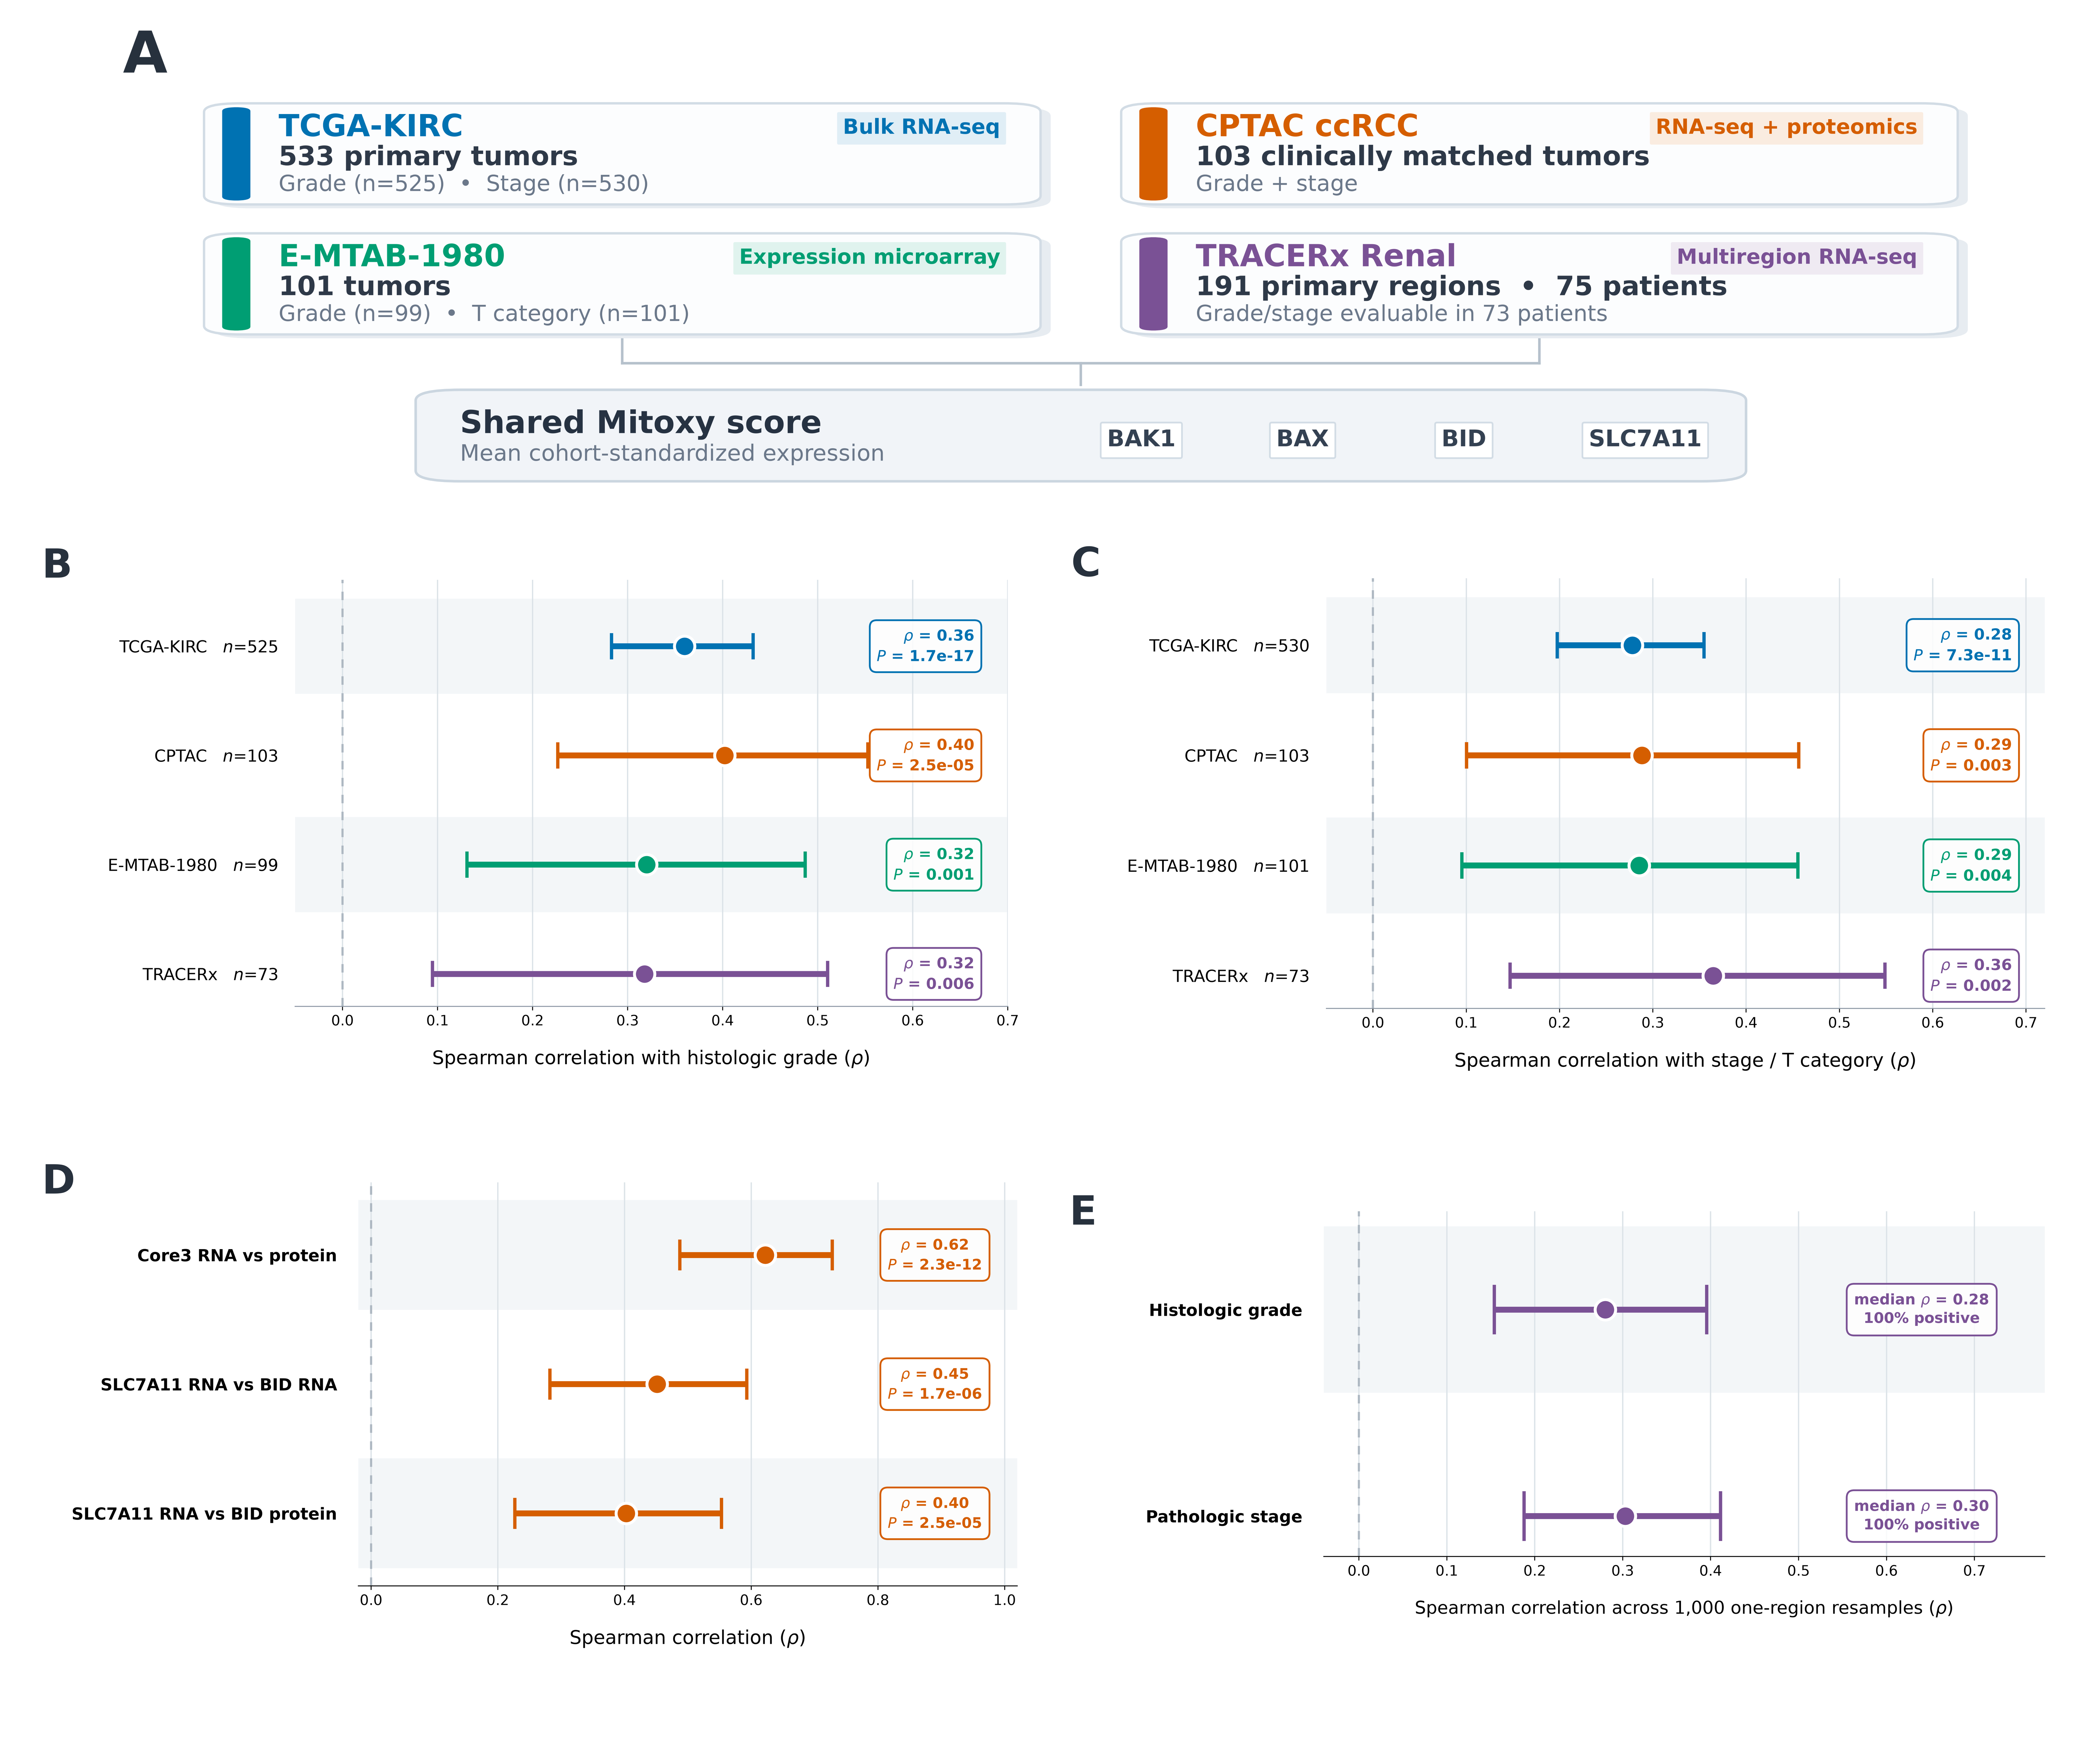

In [14]:
panel_paths = {
    "A": panel_a_paths["png"],
    "B": panel_b_paths["png"],
    "C": panel_c_paths["png"],
    "D": panel_d_paths["png"],
    "E": panel_e_paths["png"],
}


def trim_white(image, padding=30, threshold=8):
    rgb = image.convert("RGB")
    difference = ImageChops.difference(
        rgb, PILImage.new("RGB", rgb.size, "white")
    ).convert("L")
    box = difference.point(lambda value: 255 if value > threshold else 0).getbbox()
    if box is None:
        return rgb
    left, top, right, bottom = box
    return rgb.crop((max(0, left-padding), max(0, top-padding),
                     min(rgb.width, right+padding), min(rgb.height, bottom+padding)))


def place(canvas, image, box, padding=20):
    x, y, width, height = box
    resized = ImageOps.contain(
        image, (width - 2*padding, height - 2*padding),
        method=PILImage.Resampling.LANCZOS,
    )
    canvas.paste(resized, (x + (width-resized.width)//2,
                           y + (height-resized.height)//2))


images = {key: trim_white(PILImage.open(path)) for key, path in panel_paths.items()}

canvas = PILImage.new("RGB", (6400, 5400), "white")
boxes = {
    "A": (100, 45, 6200, 1480),
    "B": (100, 1595, 3055, 1760),
    "C": (3245, 1595, 3055, 1760),
    "D": (100, 3425, 3055, 1760),
    "E": (3245, 3425, 3055, 1760),
}

for key in "ABCDE":
    place(canvas, images[key], boxes[key])

final_paths = {
    "png": FIGURE_DIR / "Figure1_revised_complete.png",
    "tiff": FIGURE_DIR / "Figure1_revised_complete.tiff",
    "pdf": FIGURE_DIR / "Figure1_revised_complete.pdf",
}

canvas.save(final_paths["png"], dpi=(300, 300), optimize=True)
canvas.save(final_paths["tiff"], dpi=(300, 300), compression="tiff_lzw")
canvas.save(final_paths["pdf"], resolution=300)

print("Final outputs:")
for path in final_paths.values():
    print(path)

display(DisplayImage(filename=str(final_paths["png"]), width=1200))